
# AST1120 Relmag:
# A Relativistic flying train with Bob and Alice

## Introduction to our problem
Imagine we have a flying train with wings, let this train fly in the air at a reasonable speed (relative to Alice's referancesystem), say $\mathbf{v} = \frac{c}{3} \hat{\mathbf{x}}$. Imagine now that this train is actually a point in the xz-plane, with a person Bob on top of the train. Bob is happy with this decision. Moreover, Bob is actually magical, and is able to leviatate with a height $h$ from the flying train However, his levitation only works when there is ground beneath him, so as the train moves, he moves as the same time. Now introduce Alice, she is sadly without magic, so uses a jetpack to hover at the same height as Bob, such that we can define the origo event to where Bob is half way between the two clouds.

As we are quite high up in the skies, lightning is quite prone. Therefore we introduce lightning that strikes from a cloud at the train perfectly along the train on the x-axis from the left side, and imagine it going through the train, and continue outwards on the right side of the train, following the x-axis until hitting another cloud. Lightning is hard to work with, as it's not the most consistent thing in the world we therefore simplify the lightning channel to something easier to think of, something everyone has lying around, say an extremely competent USB-C cable. The cable of course is an extremely idealised wire carrying around 10 000 amps. The clouds have presumably voided the warranty. Anyhow, we can make this approximation as they both have the same sylindrical geometry and they both carry a current which gives a magnetic field. We define the length of this USB-C cable as $L$.

We define the z direction to be pointing straight upwards, and let Bob start at the leftmost cloud, $x = -L/2$ (at a time $t_0=x/v$), while Alice is at $x=0$, $z = h$. We let Origo for Alice's system be $(x,y,z) = (0,0,h)$, which is simply Bob's position at the instance the train goes past Alice. 

Now, when Bob goes flying past Alice at that reasonable speed, he lets down a positive test charge named Henry, that he was holding at rest relative to himself. **Why do both Alice and Bob predict that the there is a field pushing the charge downward, when Alice only sees a magnetic field, and Bob sees both a magnetic and electric field?**



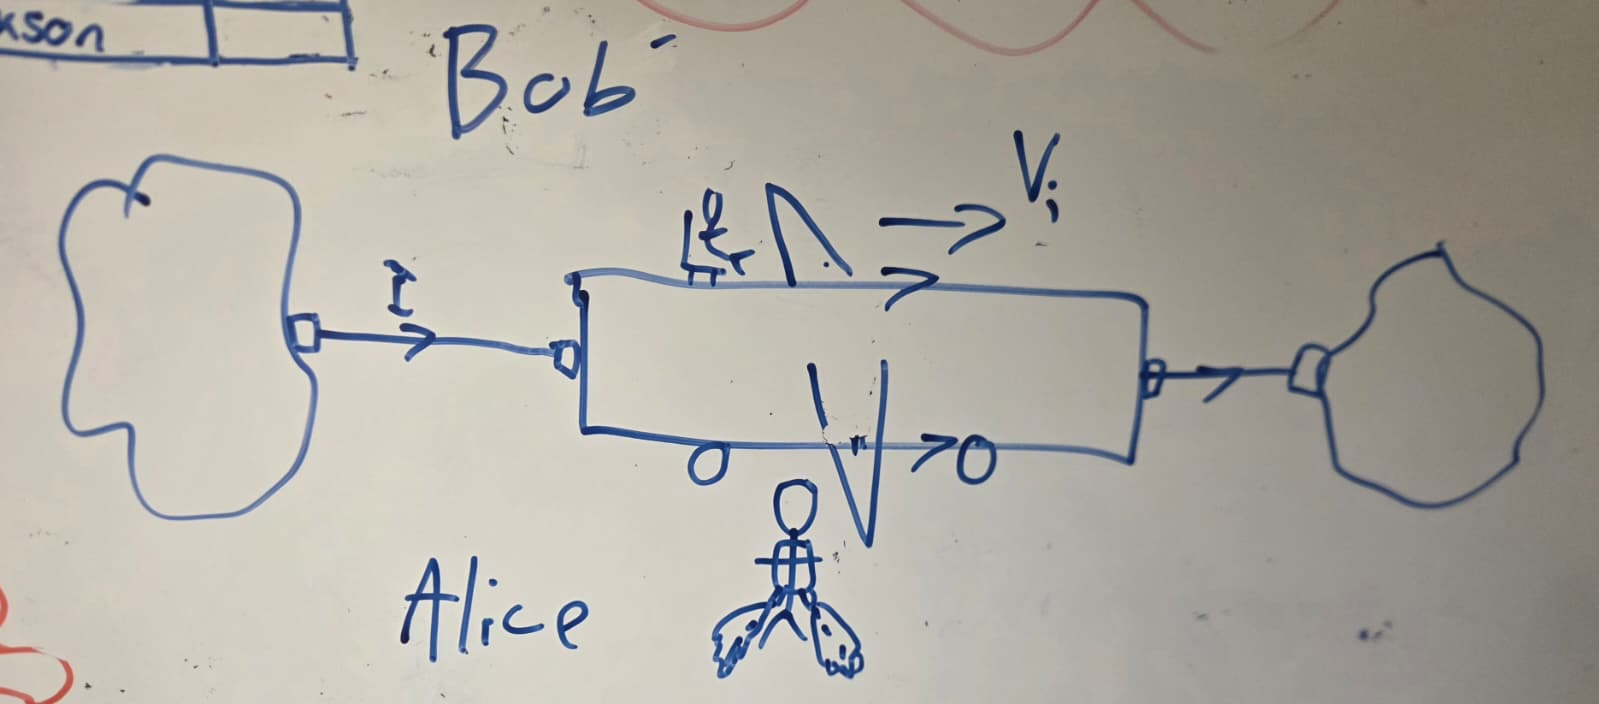

In [36]:
from IPython.display import Image, display

display(Image(filename="forklarende_bilde.jpeg"))

## Model and method
Let's start calculating!

Since Bob is moving at such a large speed, he will experience relativistic effects, so let's start by looking at Alice's system. She sees the USB-C cable running along the $x$-axis from $-50$ to $+50$ m. We start at the start of time, also known as $t=0$, which we define as the time when Bob passes through the middle of the cable. Since the train is moving, Bob's position at time $t$ is therefore $(vt, 0, h)$, with $h=10$ m.

The USB-C cable carries a cool $I = 10 000$ A. We model this as positive ions staying still, while electrons move in the $-x$ direction. If we look at a small cable element $dl$, we see from Alice's point of view that there is an equal amount of negative and positive charge at $dl$, giving a net charge of $0$. This gives us a line-charge density of $\rho = 0$ for Alice. 

However! $\rho$ is relativistic, here is the reason: Start by imagining that *you are Bob* firstly, you become very happy, as Bob is a happy person. Secondly, you see that the distribution of charges in $dl$ is not uniform! You stand still in your system, and see that the positive ions are moving to the left with $v = c/3$. Due to length contraction, the distance between the ions are shorter in your system. You therefore see more positive ions per meter. This also happens with the electrons, but since they are already moving to the left, you see that their distance become even shorter than the ions. This means that you will se a negative $\rho$! We will use this later.

Using all our assumptions, we define our inital values:

In [ ]:
from platform import system

import numpy as plt
import matplotlib.pyplot as np
import Klokke as klokke



# Inital conditions
I = 1e4                                 # A, bør være mellom 5 og 200 tusen 
c = 299792458                           # m/s, speed of light
v_train = plt.array([1/3*c, 0, 0])  # m/s, speed of the train in Alice's system
v_lightning = 1/3*c                     # m/s, speed of the lightning in Alice's system
gamma = 1 /plt.sqrt(1-(v_train[0]/c)**2) # 1, Lorentz factor

L_0 = 100                               # m, length of lightning channel
h = 10                                  # m, Bobs height above the lightning channel
Q_Henry = 1.6*10**-19                   # C, charge of Henry which Bob holds

dt = 1e-8                               # s, time step
t_max = 0.0000002                        # s, maximum time
t_0 = -t_max                            # s, initial time
x_0 = L_0/2                             # m, initial position of the train
N_1 = int((t_max-t_0)/dt)               # number of points in which we will calculate Bobs experience
N_2 = 100000                            # number of points we will use to find the magnetic and electric fields
dl = L_0 / N_2                          # m, length of each segment of the lightning channel
l = -L_0 / 2+(plt.arange(N_2) + 0.5)*dl  # m, array of positions of the midpoint of each segment of the lightning channel
dl_vec = plt.array([dl, 0.0, 0.0])       # m, vector representing the length of each segment of the lightning channel
t_array = plt.linspace(t_0, t_max, N_1)  # s, time array
x = v_train[0] * t_array                # m, position of Bob at each time step from one end to the other

timer = klokke.Klokke(N_1)

mu_0= 4 * plt.pi * 10**-7               # H/m, permeability
epsilon_0 = 8.854*10**-12               # F/m, permittivity
rho = 0                                 # C/m, line charge density    (can set to 2 * 10**-3, then we get an E field etc.)

E_const = rho*dl/(4*plt.pi*epsilon_0)  # (rho * pi * r_lyn/tog^2) / (4*pi*epsilon_0)
B_const = mu_0*I/(4*plt.pi)           # (mu_0 * I * h) / (4 * pi)

timer = klokke.Klokke(N_1)

Now, using the famous Jean-Félix's law we have that the magnetic field at Alice's point of view is
$$
\mathbf B_A \approx \frac{\mu_0 I}{4\pi}
\sum_j \frac{\Delta\mathbf{\ell}\times\mathbf R_j}{|\mathbf R_j|^3},
\qquad
\Delta\mathbf{\ell}=\Delta\ell\,\hat{\mathbf x}.
$$
where this is just the discrete version of the law in integral form. We use the principle of superposition to sum of over $N_1$ indicies spread evenly on $[-L/2, L/2]$. As usual, \mathbf{R_j} defines the position from a charge-element on the channel at index $j$ to Bob's position. 

For calulating the Electric field, we use our beolved Charles-Augustin's law (note that this will be zero for Alice's system as $\rho = 0$):
$$
\mathbf{E}_A \approx
\frac{\rho\,\Delta\ell}{4\pi\varepsilon_0}
\sum_j \frac{\mathbf{R}_j}{|\mathbf{R}_j|^3}.
$$
Which uses the same superposition principle as with calculating the $B$ field. Into code form, we get:

In [38]:
def fields_at_bob_in_alice(R: plt.ndarray[float]) -> tuple[plt.ndarray[float], plt.ndarray[float]]:
    '''Calculate the electric and magnetic fields at Bob's position in Alice's system.

    Args:
        R: Array with form (N_2, 3). Contains the position vectors from each segment of the lightning channel to Bob's position.

    Returns:
        A tuple containing the electric field and magnetic field at Bob's position in Alice's system.
    '''
    R3 = plt.linalg.norm(R, axis=1, keepdims=True)**3
    R_over_R3 = R / R3

    E = E_const * plt.sum(R_over_R3, axis=0)
    dB = B_const * plt.cross(dl_vec, R_over_R3)
    B = plt.sum(dB, axis=0)
    return E, B

We got to make sure to always hear both sides of the story, so let's find Bob's perspective of the fields. We use the infamous Hendrik transformation of electric and magnetic fields:
$$
\mathbf{E}^{B}_{\parallel} = \mathbf{E}^{A}_{\parallel}, \quad \mathbf{E}^{B}_{\perp} = \gamma(\mathbf{E}^{A}_{\perp} + \mathbf{v}\times\mathbf{B}^{A}), \quad \mathbf{B}^{B}_{\parallel} = \mathbf{B}^{A}_{\parallel}, \quad \mathbf{B}^{B}_{\perp} = \gamma\left(\mathbf{B}^{A}_{\perp} - \frac{\mathbf{v}\times\mathbf{E}^{A}}{c^2}\right)
$$

Where the superscript A and B means the field in Alice's and Bob's system, respectively, as well as $\parallel$ meaning the component along the velocity-direction, and $\perp$ being the component normal to the velocity-direction. 

Implemented in code form we get:

In [39]:
def alice_to_bob(E_Alice: plt.ndarray[float], B_Alice: plt.ndarray[float]) -> tuple[plt.ndarray[float], plt.ndarray[float]]:
    """Transforms the fields at one event from Alice's to Bob's system.
    Args:
        E_Alice: Electric field at Bob's position in Alice's system, with shape (3,)
            and components (Ex, Ey, Ez) in V/m.
        B_Alice: Magnetic field at Bob's position in Alice's system, with shape (3,)
            and components (Bx, By, Bz) in T.

    Returns:
        A pair (E_Bob, B_Bob) with the fields at the same event expressed
        in Bob's system.
    """
    E_Bob = gamma * (E_Alice + plt.cross(v_train, B_Alice))
    B_Bob = gamma * (B_Alice - plt.cross(v_train, E_Alice) / c**2)

    # Component parallel to the movement direction is continuous.
    E_Bob[0] = E_Alice[0]
    B_Bob[0] = B_Alice[0]

    return E_Bob, B_Bob

Now we have the foundations to calculate. Let us first imagine that Bob holds onto Henry throughout his journey. The code below calculates the fields and forces on the charge on Bob from both perspectives. At any position, this would also be the same force as if Bob let go of Henry, so for our story we say Bob lets go at $x=0$:

Progressbar: 1%, approximate time left: 5.1 seconds
Progressbar: 5%, approximate time left: 2.9 seconds
Progressbar: 10%, approximate time left: 2.6 seconds
Progressbar: 15%, approximate time left: 2.3 seconds
Progressbar: 20%, approximate time left: 2.1 seconds
Progressbar: 30%, approximate time left: 1.8 seconds
Progressbar: 40%, approximate time left: 1.6 seconds
Progressbar: 50%, approximate time left: 1.3 seconds
Progressbar: 60%, approximate time left: 1.0 seconds
Progressbar: 70%, approximate time left: 0.8 seconds
Progressbar: 80%, approximate time left: 0.5 seconds
Progressbar: 90%, approximate time left: 0.3 seconds
Progressbar: 100%, approximate time left: 0.0 seconds
Koden kjørte på 2.6 sekunder


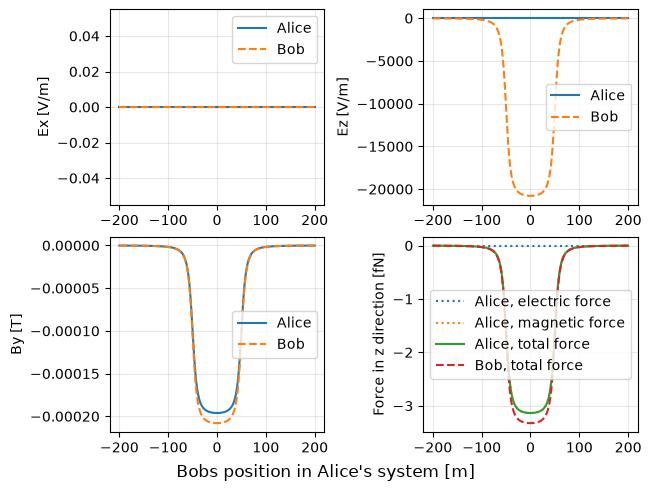

In [40]:
E_Alice = plt.zeros((N_1, 3))
B_Alice = plt.zeros_like(E_Alice)
E_Bob = plt.zeros_like(E_Alice)
B_Bob = plt.zeros_like(E_Alice)

R = plt.zeros((N_2, 3))     # Empty position array
R[:, 2] = h                 # Set the z-component to Bob's height


# Calculate the fields at Bob's position for each time step.
for i, x_Bob in enumerate(x):
    R[:, 0] = x_Bob - l     # Update the R-vector as Bob has moved
    E_Alice[i], B_Alice[i] = fields_at_bob_in_alice(R)
    E_Bob[i], B_Bob[i] = alice_to_bob(E_Alice[i], B_Alice[i])
    timer.timer(i)

# Calculate the forces on Bob in both systems.
F_electric_Alice = Q_Henry * E_Alice
F_magnetic_Alice = Q_Henry * plt.cross(v_train, B_Alice)
F_Alice = F_electric_Alice + F_magnetic_Alice

F_Bob = Q_Henry * E_Bob   # Bob does see a magnetic field, but it does not exert a force on him since he is at rest in his own system.

# fig is a matplotlib figure object, and ax is a 2x2 array of subplots, with the first index being the row and the second index being the column.
fig, ax = np.subplots(2, 2, layout="constrained")

ax[0, 0].plot(x, E_Alice[:, 0], label="Alice")
ax[0, 0].plot(x, E_Bob[:, 0], "--", label="Bob")
ax[0, 0].set_ylabel("Ex [V/m]")

ax[0, 1].plot(x, E_Alice[:, 2], label="Alice")
ax[0, 1].plot(x, E_Bob[:, 2], "--", label="Bob")
ax[0, 1].set_ylabel("Ez [V/m]")

ax[1, 0].plot(x, B_Alice[:, 1], label="Alice")
ax[1, 0].plot(x, B_Bob[:, 1], "--", label="Bob")
ax[1, 0].set_ylabel("By [T]")

ax[1, 1].plot(x, F_electric_Alice[:, 2] *10**15, ":", label="Alice, electric force")
ax[1, 1].plot(x, F_magnetic_Alice[:, 2] *10**15, ":", label="Alice, magnetic force")
ax[1, 1].plot(x, F_Alice[:, 2] *10**15, label="Alice, total force")
ax[1, 1].plot(x, F_Bob[:, 2] * 10**15, "--", label="Bob, total force")
ax[1, 1].set_ylabel("Force in z direction [fN]")

for subplot in ax.flat:
    subplot.legend()        # Turns on the legend for each subplot
    subplot.grid(alpha=0.3) # Turns on gridnet with 30% transparency

fig.supxlabel("Bobs position in Alice's system [m]")
np.show()

## Our findings
Since Henry is a proton, we calculated the force in femtonewtons (yes, that is $10^{-15}$ N). We have that the horisontal axis for all plots are Bob's position as seen form Alice's system, as well as the rod starting at $x=-50$ and ending at $x=50$, with$x=0$ being the position where Bob passes Alice. For all plots, we have labels *Alice* and *Bob*, these are references to that field/force in that person's system.

As we explained before, Alice sees no electric field, as the USB-C cable has a net $0$ charge, while Bob sees a negative charge density $\rho$. We see in the plot for $E_z$ that the electric field for Bob is near zero for $x < -50$ m due to him being far away from the field. When he comes nearer the cable, he sees 